# BHDAC Case Competition: Credit Risk Model and Underwriting Strategy

Runs on the output of the rename notebook: `U_of_DE_Comp_renamed.csv` and `column_lookup.csv` (same folder).

## What makes this different

Most teams will fit an XGBoost model, report an AUC, and cut the predictions into four tiers. This notebook builds what a bank's credit risk team would actually approve:

1. **Sentinel codes become signal, not noise.** Codes like 9996 or 98 are not numbers, and they are not random missing values either. Each one gets its own flag so the model can learn what "no record" vs "not applicable" means for risk.
2. **Leakage audit.** `bal_24m` and `line_24m` are labeled *Performance*. If the bank cut a line *because* the borrower defaulted, using those columns would fake a great AUC. We test this before trusting any trajectory features.
3. **Monotonic constraints.** More delinquencies can never lower predicted risk, and a higher score can never raise it. Regulators (ECOA / Reg B) require models that make sense and can be explained. We show this costs almost nothing in accuracy.
4. **We beat the bureau score, and show it.** Every metric is compared to Score1 / Score2 alone, using industry metrics (AUC, Gini, KS).
5. **Two targets, one insight.** Borrowers who default on *another* lender's account first are an early warning. A second model on `consumer_bad_flg_90plus_24m` builds a watchlist of accounts that look fine here but are failing elsewhere.
6. **Reason codes.** SHAP values turn every prediction into the top 3 plain-English reasons, the same thing a lender must send in an adverse action notice.
7. **Tiers set by profit, not by quantile.** The High Risk cutoff is the break-even PD where expected loss exceeds expected interest income. Each tier gets a credit line action, and we report the expected profit vs doing nothing.

## 1. Setup

If `import xgboost` fails, run this once in your terminal with your conda env active:
`pip install xgboost scikit-learn matplotlib`

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)
SEED = 42

TARGET = "bad_flg_90plus_24m"                     # defaulted on THIS account
TARGET_CONSUMER = "consumer_bad_flg_90plus_24m"   # defaulted on ANY account

### Economic assumptions

These drive the profit-based tiers and the credit line strategy. They are assumptions, so **state them on a slide** and change them here if the case gives different numbers.

- **APR**: interest rate charged on balances
- **COST_OF_FUNDS**: what the bank pays to fund those balances
- **LGD** (loss given default): share of the exposure lost when an account defaults
- **CCF** (credit conversion factor): share of the *unused* line a borrower draws before defaulting
- **NEW_LINE_UTIL**: share of a line increase that Prime borrowers actually use

In [2]:
APR = 0.22
COST_OF_FUNDS = 0.05
LGD = 0.85
CCF = 0.50
YEARS = 2              # matches the 24-month performance window
NEW_LINE_UTIL = 0.15

## 2. Load the renamed data and drop Noise columns

In [3]:
df = pd.read_csv("U_of_DE_Comp_renamed.csv")
lookup = pd.read_csv("column_lookup.csv")

noise_cols = list(lookup.loc[lookup["Field Type"] == "Noise", "New Name"])
performance_cols = list(lookup.loc[lookup["Field Type"] == "Performance", "New Name"])
df = df.drop(columns=[c for c in noise_cols if c in df.columns])

print(df.shape)
print(f"Account default rate:  {df[TARGET].mean():.2%}")
print(f"Consumer default rate: {df[TARGET_CONSUMER].mean():.2%}")

(300000, 36)
Account default rate:  6.31%
Consumer default rate: 9.12%


## 3. Find and resolve sentinel codes (case goal 2)

A **sentinel code** is a fake number that stands for a status, like 9996 = "no qualifying trades". If left alone, the model treats 9996 months as a real (huge) value and averages get wrecked.

**How we find them, step by step:**
1. A value *looks like a code* if it is all 9s ending in a digit from 2 to 9 (98, 996, 9998, 999999996) or a 9, then zeros, then a digit (9003).
2. It only counts as a sentinel if it is **above every real value** in that column. So 95 months is kept as real in a column where real values go up to 390, but 98 is a code in a column where real values stop at 40.

In [4]:
def looks_like_code(v):
    s = str(int(v))
    nines_then_digit = len(s) >= 2 and set(s[:-1]) == {"9"} and s[-1] in "23456789"
    nine_zeros_digit = len(s) >= 4 and s[0] == "9" and set(s[1:-1]) == {"0"}
    return nines_then_digit or nine_zeros_digit

check_cols = [c for c in df.columns
              if c not in [TARGET, TARGET_CONSUMER] and pd.api.types.is_numeric_dtype(df[c])]

sentinels = {}
for col in check_cols:
    values = pd.Series(df[col].dropna().unique())
    is_code = values.apply(looks_like_code)
    real_max = values[~is_code].max()
    codes = sorted(values[is_code & (values > real_max)])
    if len(codes) > 0:
        sentinels[col] = codes

print(f"{len(sentinels)} columns contain sentinel codes")

24 columns contain sentinel codes


### Sentinel audit: do the codes carry risk signal?

For each code: how many rows have it, and the default rate for those rows vs rows with a real value. If the rates differ a lot, imputing the median would destroy real information. That is the argument for keeping a flag.

In [5]:
rows = []
for col, codes in sentinels.items():
    real = ~df[col].isin(codes)
    for code_value in codes:
        mask = df[col] == code_value
        rows.append({
            "column": col,
            "code": int(code_value),
            "rows": int(mask.sum()),
            "pct_of_rows": mask.mean() * 100,
            "default_rate_code_%": df.loc[mask, TARGET].mean() * 100,
            "default_rate_real_%": df.loc[real, TARGET].mean() * 100,
        })

audit = pd.DataFrame(rows).sort_values("pct_of_rows", ascending=False).reset_index(drop=True)
audit.round(2)

,column,code,rows,pct_of_rows,default_rate_code_%,default_rate_real_%
0,months_since_recent_30dpd,9996,204132,68.04,4.90,9.19
1,num_active_revolving_bankcards_3m,98,23432,7.81,13.05,5.68
2,util_revolving_bankcards_3m,998,23432,7.81,13.05,5.07
3,util_revolving_bankcards_3m,997,13365,4.46,11.95,5.07
4,util_overall_open_trades,996,9713,3.24,15.02,5.95
5,util_highest_balance_trade_3m,996,6285,2.10,16.52,5.93
6,util_revolving_bankcards_3m,996,5871,1.96,17.99,5.07
7,credit_score_2,9003,4507,1.50,12.67,6.13
8,util_highest_balance_trade_3m,997,4090,1.36,12.59,5.93
9,credit_score_2,9002,3673,1.22,12.58,6.13


### Convert codes without distorting the data

For each column with codes:
1. `<col>_code` keeps **which** code appeared (0 = a real value was reported).
2. `<col>` itself gets `NaN` where the code was. XGBoost handles `NaN` natively: at each split it learns which side missing values should go. So nothing is imputed, nothing is made up.

In [6]:
for col, codes in sentinels.items():
    is_code = df[col].isin(codes)
    df[col + "_code"] = df[col].where(is_code, 0)
    df[col] = df[col].where(~is_code, np.nan)

df.filter(like="_code").head()

,months_longest_satisfactory_streak_code,num_active_revolving_bankcards_3m_code,num_open_trades_code,num_trades_opened_3m_code,months_since_oldest_trade_code,num_trades_with_balance_code,pct_trades_never_delinquent_code,num_bankruptcy_trades_code,num_trades_ever_charged_off_code,num_unsatisfied_chargeoffs_code,bal_unsatisfied_chargeoffs_code,num_trades_ever_30plus_dpd_code,num_trades_now_30dpd_6m_code,num_trades_now_90_180dpd_6m_code,num_trades_30plus_dpd_12m_code,num_trades_90dpd_24m_code,months_since_recent_30dpd_code,num_first_payment_defaults_12m_code,num_30dpd_occurrences_24m_code,num_trades_repossessed_code,credit_score_2_code,util_overall_open_trades_code,util_highest_balance_trade_3m_code,util_revolving_bankcards_3m_code
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,9996,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,9996,0,0,0,0,0,0,0


## 4. Feature engineering (case goal 3)

**Derogatory signals**
- `derog_count`: how many *different kinds* of serious events the borrower has (bankruptcy, charge-off, collection, repossession, judgment, 90+ DPD)
- `derog_severity`: the same events, weighted by how severe they are (bankruptcy 4, repo/charge-off 3, collections/judgments/90 DPD 2, recent 30 DPD 1)
- `recent_delinquency`: 1 if any delinquency in the last 6 to 12 months

**Score and credit-seeking behavior**
- `score_avg`, `score_gap` (Score1 minus Score2)
- `inquiries_per_trade`, `new_trade_share`: applying for lots of credit relative to file size
- `thin_file`: under 2 years of history or 2 or fewer open trades
- `util_max`: the highest of the three utilization measures

In [7]:
severity = {
    "num_bankruptcy_trades": 4,
    "num_trades_repossessed": 3,
    "num_trades_ever_charged_off": 3,
    "num_unsatisfied_chargeoffs": 3,
    "num_unsatisfied_collections": 2,
    "num_judgments_over_1000": 2,
    "num_trades_90dpd_24m": 2,
    "num_trades_now_30dpd_6m": 1,
}

df["derog_count"] = (df[list(severity)] > 0).sum(axis=1)

df["derog_severity"] = 0
for col, weight in severity.items():
    df["derog_severity"] = df["derog_severity"] + (df[col] > 0) * weight

df["recent_delinquency"] = ((df["num_trades_now_30dpd_6m"] > 0)
                            | (df["num_trades_now_90_180dpd_6m"] > 0)
                            | (df["num_trades_30plus_dpd_12m"] > 0)).astype(int)

df["score_avg"] = df[["credit_score_1", "credit_score_2"]].mean(axis=1)
df["score_gap"] = df["credit_score_1"] - df["credit_score_2"]

df["inquiries_per_trade"] = df["num_inquiries_12m"] / (df["num_open_trades"] + 1)
df["new_trade_share"] = df["num_trades_opened_3m"] / (df["num_open_trades"] + 1)
df["thin_file"] = ((df["months_since_oldest_trade"] < 24) | (df["num_open_trades"] <= 2)).astype(int)
df["util_max"] = df[["util_overall_open_trades", "util_highest_balance_trade_3m",
                     "util_revolving_bankcards_3m"]].max(axis=1)

df.groupby("derog_count")[TARGET].agg(["count", "mean"]).rename(columns={"mean": "default_rate"})

,count,default_rate
derog_count,,
0,217058,0.028453
1,40956,0.114660
2,17012,0.128439
3,17682,0.214399
4,6106,0.272683
5,1084,0.338561
6,101,0.415842
7,1,0.000000


**Trajectory features** (credit limit and balance change from 12m to 24m), as the case asks:
- `line_change`, `line_change_pct`: did the bank raise or cut the limit?
- `bal_change`: did the balance grow or shrink?
- `util_12m`, `util_24m`, `util_change`: balance / limit at each point

These come from **Performance** columns, so they are audited in the next step before we use them.

In [8]:
df["line_change"] = df["line_24m"] - df["line_12m"]
df["line_change_pct"] = df["line_change"] / df["line_12m"].replace(0, np.nan)
df["bal_change"] = df["bal_24m"] - df["bal_12m"]
df["util_12m"] = df["bal_12m"] / df["line_12m"].replace(0, np.nan)
df["util_24m"] = df["bal_24m"] / df["line_24m"].replace(0, np.nan)
df["util_change"] = df["util_24m"] - df["util_12m"]

trajectory_cols = ([c for c in df.columns if c.startswith(("bal_12m", "bal_24m", "line_12m", "line_24m"))]
                   + ["line_change", "line_change_pct", "bal_change", "util_12m", "util_24m", "util_change"])

bureau_features = [c for c in df.columns
                   if c not in performance_cols and c not in trajectory_cols]

print(len(bureau_features), "bureau features")
print(len(trajectory_cols), "trajectory features")

63 bureau features
10 trajectory features


## 5. Train / validation / test split

- **Train (60%)**: the model learns from this
- **Validation (20%)**: used to decide when to stop adding trees (early stopping)
- **Test (20%)**: never touched until the end. Every number we present comes from here.

`stratify` keeps the 6.31% default rate the same in all three pieces.

In [9]:
train, temp = train_test_split(df, test_size=0.4, stratify=df[TARGET], random_state=SEED)
valid, test = train_test_split(temp, test_size=0.5, stratify=temp[TARGET], random_state=SEED)
test = test.copy()

print(f"train {len(train):,} | valid {len(valid):,} | test {len(test):,}")

train 180,000 | valid 60,000 | test 60,000


### Helper functions

- **AUC**: chance the model ranks a random defaulter above a random non-defaulter (0.5 = coin flip, 1.0 = perfect)
- **Gini** = 2 x AUC - 1, the number credit risk teams quote
- **KS**: the largest gap between the defaulter and non-defaulter score distributions. Above 0.40 is strong in consumer credit.

No `scale_pos_weight` is used for the 6% imbalance on purpose: reweighting inflates the predicted probabilities, and the profit math needs real probabilities.

In [10]:
def ks_stat(y, p):
    fpr, tpr, _ = roc_curve(y, p)
    return (tpr - fpr).max()

def score_model(name, y, p):
    auc = roc_auc_score(y, p)
    return {"model": name, "AUC": round(float(auc), 4), "Gini": round(float(2 * auc - 1), 4),
            "KS": round(float(ks_stat(y, p)), 4)}

def fit_xgb(features, target, monotone=None):
    model = xgb.XGBClassifier(
        n_estimators=3000,
        learning_rate=0.03,
        max_depth=4,
        min_child_weight=20,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        tree_method="hist",
        eval_metric="auc",
        early_stopping_rounds=150,
        monotone_constraints=monotone,
        random_state=SEED,
        n_jobs=-1,
    )
    model.fit(train[features], train[target],
              eval_set=[(valid[features], valid[target])], verbose=False)
    return model

def predict(model, data, features):
    return model.predict_proba(data[features])[:, 1]

## 6. Leakage audit on the trajectory features

**Leakage** = a feature that contains information you would not have when making the decision. Here's the risk:
1. A borrower goes 90+ days late (default).
2. The bank responds by cutting the line and charging off the balance.
3. `line_24m` and `bal_24m` now *reflect* the default, so they "predict" it perfectly.

**Test:** train one model with bureau features only and one with trajectory features added, then look at:
- the AUC jump (a huge jump is a red flag), and
- the default rate by line direction (if almost every line cut is a defaulter, the cut came *after* the default).

In [11]:
m_bureau = fit_xgb(bureau_features, TARGET)
m_traj = fit_xgb(bureau_features + trajectory_cols, TARGET)

auc_bureau = roc_auc_score(test[TARGET], predict(m_bureau, test, bureau_features))
auc_traj = roc_auc_score(test[TARGET], predict(m_traj, test, bureau_features + trajectory_cols))

print(f"Bureau only AUC:        {auc_bureau:.4f}")
print(f"Bureau + trajectory AUC: {auc_traj:.4f}   (jump: {auc_traj - auc_bureau:+.4f})")

direction = np.sign(df["line_change"]).map({-1: "line cut", 0: "no change", 1: "line increase"})
df.groupby(direction)[TARGET].agg(["count", "mean"]).rename(columns={"mean": "default_rate"})

Bureau only AUC:        0.8562
Bureau + trajectory AUC: 0.9618   (jump: +0.1056)


,count,default_rate
line_change,,
line cut,19684,0.019254
line increase,55549,0.008425
no change,224767,0.080417


### Decision: use trajectory features or not?

- **Small jump (under ~0.02) and line cuts have a moderately higher default rate:** the trajectory is a real early-warning signal. Set `USE_TRAJECTORY = True` and pitch it as an **account management** model (re-scoring existing accounts each month).
- **Big jump (0.05+) or line cuts are mostly defaulters:** that's leakage. Keep `USE_TRAJECTORY = False`, and say on a slide that you caught it. Judges remember the team that found the trap.

If you can, ask the organizers whether `_12m` / `_24m` mean "12 / 24 months **ago**" (safe history) or "month 12 / 24 **of the performance window**" (leakage).

In [12]:
USE_TRAJECTORY = False

features = bureau_features + (trajectory_cols if USE_TRAJECTORY else [])
unconstrained = m_traj if USE_TRAJECTORY else m_bureau
print(len(features), "features in the final model")

63 features in the final model


## 7. Final model with monotonic constraints

A **monotonic constraint** forces the model's prediction to only go one way as a feature increases:
- `+1`: more of this can only **raise** predicted risk (delinquencies, charge-offs, utilization, inquiries)
- `-1`: more of this can only **lower** predicted risk (score, file age, months since last delinquency)

Without it, XGBoost can learn something like "4 delinquencies is safer than 3" from noise in the data. A bank can't defend that to a regulator or a customer.

In [13]:
increasing = [
    "num_trades_ever_30plus_dpd", "num_trades_now_30dpd_6m", "num_trades_now_90_180dpd_6m",
    "num_trades_30plus_dpd_12m", "num_trades_90dpd_24m", "num_30dpd_occurrences_24m",
    "num_first_payment_defaults_12m", "num_bankruptcy_trades", "num_ch7_bankruptcies",
    "num_ch13_bankruptcies", "num_trades_ever_charged_off", "num_unsatisfied_chargeoffs",
    "bal_unsatisfied_chargeoffs", "num_unsatisfied_collections", "num_judgments_over_1000",
    "num_trades_repossessed", "num_inquiries_12m", "util_overall_open_trades",
    "util_highest_balance_trade_3m", "util_revolving_bankcards_3m", "util_max",
    "derog_count", "derog_severity", "recent_delinquency",
]
decreasing = [
    "months_longest_satisfactory_streak", "months_since_oldest_trade",
    "pct_trades_never_delinquent", "months_since_recent_30dpd",
    "credit_score_1", "credit_score_2", "score_avg",
]

monotone = {c: 1 for c in increasing if c in features}
monotone.update({c: -1 for c in decreasing if c in features})

model = fit_xgb(features, TARGET, monotone)
test["pd_account"] = predict(model, test, features)

print(f"{len(monotone)} constrained features | trees used: {model.best_iteration + 1}")

31 constrained features | trees used: 392


### Scorecard: model vs the bureau score alone (test set)

For the score-only rows, the prediction is just *minus* the score (lower score = riskier). This is the "what the bank already has" baseline.

In [14]:
def score_only(col):
    return -test[col].fillna(test[col].median())

results = pd.DataFrame([
    score_model("Score1 alone", test[TARGET], score_only("credit_score_1")),
    score_model("Score2 alone", test[TARGET], score_only("credit_score_2")),
    score_model("XGBoost, unconstrained", test[TARGET], predict(unconstrained, test, features)),
    score_model("XGBoost, monotonic (final)", test[TARGET], test["pd_account"]),
])
results

,model,AUC,Gini,KS
0,Score1 alone,0.8430,0.6860,0.5385
1,Score2 alone,0.8270,0.6540,0.4888
2,"XGBoost, unconstrained",0.8562,0.7124,0.5536
3,"XGBoost, monotonic (final)",0.8548,0.7096,0.5514


### Decile table: ranking and calibration

Sort test accounts by predicted PD and cut them into 10 equal groups (10 = riskiest).
- **actual_rate** should rise smoothly from decile 1 to 10. That shows the ranking works.
- **predicted_pd vs actual_rate** should be close in every decile. That shows the probabilities are honest, which the profit math depends on.
- **capture_%**: share of all defaults caught in that decile. The top 2 to 3 deciles catching most defaults is the headline.

In [15]:
test["decile"] = pd.qcut(test["pd_account"].rank(method="first"), 10, labels=False) + 1

deciles = test.groupby("decile").agg(
    accounts=(TARGET, "size"),
    predicted_pd=("pd_account", "mean"),
    actual_rate=(TARGET, "mean"),
    defaults=(TARGET, "sum"),
).sort_index(ascending=False)
deciles["capture_%"] = deciles["defaults"] / deciles["defaults"].sum() * 100
deciles["cumulative_capture_%"] = deciles["capture_%"].cumsum()
deciles.round(4)

,accounts,predicted_pd,actual_rate,defaults,capture_%,cumulative_capture_%
decile,,,,,,
10,6000,0.3120,0.2980,1788,47.2516,47.2516
9,6000,0.1395,0.1337,802,21.1945,68.4461
8,6000,0.0764,0.0823,494,13.0550,81.5011
7,6000,0.0450,0.0485,291,7.6903,89.1913
6,6000,0.0286,0.0320,192,5.0740,94.2653
5,6000,0.0169,0.0177,106,2.8013,97.0666
4,6000,0.0087,0.0093,56,1.4799,98.5465
3,6000,0.0044,0.0053,32,0.8457,99.3922
2,6000,0.0021,0.0032,19,0.5021,99.8943


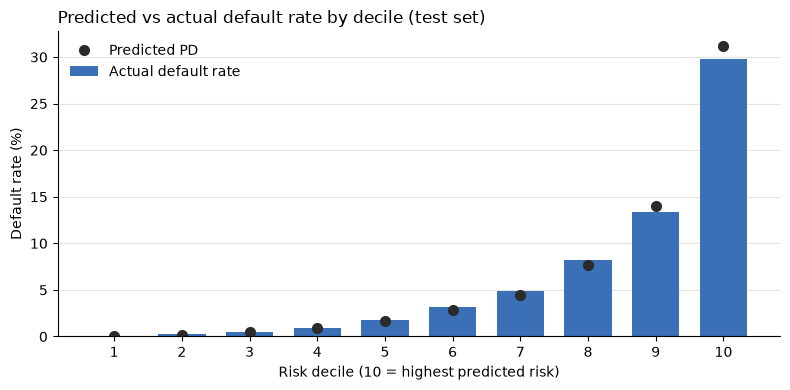

In [16]:
fig, ax = plt.subplots(figsize=(8, 4))
x = deciles.index.astype(int)
ax.bar(x, deciles["actual_rate"] * 100, width=0.7, color="#3B6FB6", label="Actual default rate")
ax.plot(x, deciles["predicted_pd"] * 100, "o", color="#2B2B2B", markersize=7, label="Predicted PD")
ax.set_xticks(x)
ax.set_xlabel("Risk decile (10 = highest predicted risk)")
ax.set_ylabel("Default rate (%)")
ax.set_title("Predicted vs actual default rate by decile (test set)", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#E3E3E3", linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 8. Second target: the cross-account early warning

The case gives two targets. Most teams model one and ignore the other. The gap between them is the insight:
- `bad_flg_90plus_24m` = defaulted on **our** account (6.31%)
- `consumer_bad_flg_90plus_24m` = defaulted on **any** account (9.12%)

So about 3% of borrowers default somewhere else **while still paying us**. Those are the accounts where a line increase is most dangerous.

**Steps:**
1. Train the same monotonic model on the consumer target.
2. `spillover_ratio` = consumer PD / account PD: how much riskier the borrower looks across all their credit than on our account alone. A ratio is used instead of a difference so the watchlist isn't just "the riskiest accounts again".
3. **Watchlist** = the top 10% of `spillover_ratio`.
4. Check: what share of the "hidden risk" borrowers (bad elsewhere, fine here) land on the watchlist? Compare against a random 10% and against simply taking the 10% with the highest **account** PD.
   - If the watchlist beats the account-PD list, the second model finds risk the first one misses. That's your slide.
   - If it doesn't, say so honestly and drop the watchlist from the strategy (set `USE_WATCHLIST = False` in section 10).

In [17]:
model_consumer = fit_xgb(features, TARGET_CONSUMER, monotone)
test["pd_consumer"] = predict(model_consumer, test, features)

print(score_model("Consumer model", test[TARGET_CONSUMER], test["pd_consumer"]))

test["spillover_ratio"] = test["pd_consumer"] / test["pd_account"]
test["watchlist"] = test["spillover_ratio"] >= test["spillover_ratio"].quantile(0.90)
top_account_pd = test["pd_account"] >= test["pd_account"].quantile(0.90)

hidden_risk = (test[TARGET] == 0) & (test[TARGET_CONSUMER] == 1)
caught = hidden_risk[test["watchlist"]].sum() / hidden_risk.sum()
caught_by_account_pd = hidden_risk[top_account_pd].sum() / hidden_risk.sum()

print(f"Hidden-risk borrowers in test: {hidden_risk.sum():,} ({hidden_risk.mean():.2%} of accounts)")
print(f"Caught by watchlist (top 10% spillover ratio): {caught:.1%}")
print(f"Caught by top 10% account PD:                 {caught_by_account_pd:.1%}")
print(f"Caught by a random 10%:                       10.0%")

test.groupby("watchlist").agg(
    accounts=(TARGET, "size"),
    account_default_rate=(TARGET, "mean"),
    consumer_default_rate=(TARGET_CONSUMER, "mean"),
).round(4)

{'model': 'Consumer model', 'AUC': 0.8633, 'Gini': 0.7267, 'KS': 0.5682}
Hidden-risk borrowers in test: 1,703 (2.84% of accounts)
Caught by watchlist (top 10% spillover ratio): 8.7%
Caught by top 10% account PD:                 41.2%
Caught by a random 10%:                       10.0%


,accounts,account_default_rate,consumer_default_rate
watchlist,,,
False,54000,0.0679,0.0966
True,6000,0.0200,0.0448


## 9. Explainability: SHAP values and reason codes

A **SHAP value** splits one prediction into pieces, one per feature: how much that feature pushed this borrower's risk up (+) or down (-) from the average. XGBoost computes them directly with `pred_contribs=True`, so no extra package is needed.

- **Global view:** average size of each feature's push across all accounts, i.e. what drives risk overall.
- **Reason codes:** for one borrower, the 3 features pushing their risk up the most. Lenders must give these reasons when they decline or cut a line (adverse action notice).

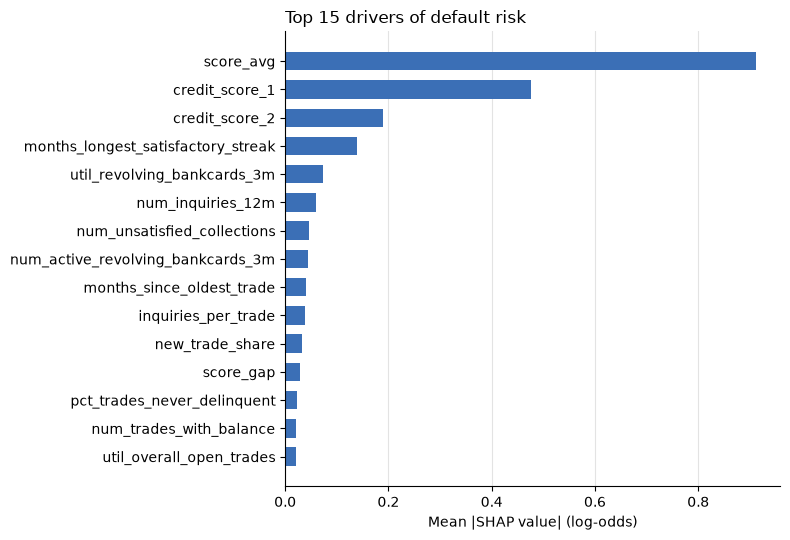

In [18]:
booster = model.get_booster()
dtest = xgb.DMatrix(test[features], missing=np.nan)
contribs = booster.predict(dtest, pred_contribs=True,
                           iteration_range=(0, model.best_iteration + 1))
shap_df = pd.DataFrame(contribs[:, :-1], columns=features, index=test.index)

importance = shap_df.abs().mean().sort_values(ascending=False)
top = importance.head(15).iloc[::-1]

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top.index, top.values, height=0.65, color="#3B6FB6")
ax.set_xlabel("Mean |SHAP value| (log-odds)")
ax.set_title("Top 15 drivers of default risk", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color="#E3E3E3", linewidth=0.8)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

In [19]:
descriptions = dict(zip(lookup["New Name"], lookup["Description"]))
descriptions.update({
    "derog_count": "Number of different types of serious derogatory events",
    "derog_severity": "Severity-weighted derogatory history",
    "recent_delinquency": "Delinquency reported in the last 6 to 12 months",
    "score_avg": "Average credit score",
    "score_gap": "Difference between the two credit scores",
    "inquiries_per_trade": "Credit inquiries relative to number of open trades",
    "new_trade_share": "Share of trades opened in the last 3 months",
    "thin_file": "Limited credit history",
    "util_max": "Highest utilization across measures",
    "credit_score_1": "Credit score 1",
    "credit_score_2": "Credit score 2",
})

def explain(feature):
    if feature.endswith("_code"):
        base = feature[:-5]
        return "Special status code reported for: " + str(descriptions.get(base, base))
    text = descriptions.get(feature)
    return text if isinstance(text, str) else feature

def reason_codes(idx, n=3):
    pushes = shap_df.loc[idx].sort_values(ascending=False)
    pushes = pushes[pushes > 0].head(n)
    return [explain(f) for f in pushes.index]

riskiest = test.sort_values("pd_account", ascending=False).head(5)
pd.DataFrame({
    "predicted_pd": riskiest["pd_account"].round(3),
    "reason_1": [reason_codes(i)[0] if len(reason_codes(i)) > 0 else "" for i in riskiest.index],
    "reason_2": [reason_codes(i)[1] if len(reason_codes(i)) > 1 else "" for i in riskiest.index],
    "reason_3": [reason_codes(i)[2] if len(reason_codes(i)) > 2 else "" for i in riskiest.index],
})

,predicted_pd,reason_1,reason_2,reason_3
5979,0.835,Average credit score,Credit score 1,Overall balance to credit limit ratio on open ...
137340,0.827,Average credit score,Credit score 1,Overall balance to credit limit ratio on open ...
82228,0.825,Average credit score,Credit score 1,Overall balance to credit limit ratio on open ...
11960,0.824,Average credit score,Credit score 1,Overall balance to credit limit ratio on open ...
208283,0.799,Average credit score,Credit score 1,Overall balance to credit limit ratio on open ...


## 10. Risk tiers set by profit (final product)

**Step 1: break-even PD.** Per dollar of credit line, with average utilization **U**:
- Expected income = (1 - PD) x U x (APR - cost of funds) x years
- Expected loss = PD x LGD x (U + CCF x (1 - U))

Set them equal and solve for PD. Above that PD, an account loses money on average, so that is the **High Risk** cutoff. It comes from economics, not an arbitrary percentile.

**Step 2: the other cutoffs** are tied to the portfolio base rate:
- **Prime**: PD below half the base rate
- **Near-Prime**: up to the base rate
- **Subprime**: base rate up to break-even
- **High Risk**: above break-even

`bal_12m` / `line_12m` are used here only to size exposure in dollars, not as model inputs.

In [20]:
U = train["bal_12m"].sum() / train["line_12m"].sum()
margin = (APR - COST_OF_FUNDS) * YEARS
breakeven_pd = (U * margin) / (U * margin + LGD * (U + CCF * (1 - U)))

base_rate = train[TARGET].mean()
PRIME_MAX = base_rate * 0.5
NEAR_PRIME_MAX = base_rate

print(f"Average utilization U: {U:.1%}")
print(f"Prime < {PRIME_MAX:.2%} | Near-Prime < {NEAR_PRIME_MAX:.2%} | "
      f"Subprime < {breakeven_pd:.2%} (break-even) | High Risk above")

tier_order = ["Prime", "Near-Prime", "Subprime", "High Risk"]
test["tier"] = pd.cut(test["pd_account"],
                      bins=[0, PRIME_MAX, NEAR_PRIME_MAX, breakeven_pd, 1],
                      labels=tier_order, include_lowest=True)

tiers = test.groupby("tier", observed=False).agg(
    accounts=(TARGET, "size"),
    avg_predicted_pd=("pd_account", "mean"),
    actual_default_rate=(TARGET, "mean"),
    defaults=(TARGET, "sum"),
    on_watchlist=("watchlist", "mean"),
)
tiers["pct_of_portfolio"] = tiers["accounts"] / tiers["accounts"].sum() * 100
tiers["share_of_defaults_%"] = tiers["defaults"] / tiers["defaults"].sum() * 100
tiers.round(4)

Average utilization U: 20.7%
Prime < 3.15% | Near-Prime < 6.31% | Subprime < 12.08% (break-even) | High Risk above


,accounts,avg_predicted_pd,actual_default_rate,defaults,on_watchlist,pct_of_portfolio,share_of_defaults_%
tier,,,,,,,
Prime,34325,0.0092,0.0102,350,0.1446,57.2083,9.2495
Near-Prime,8782,0.0447,0.0491,431,0.0687,14.6367,11.3901
Subprime,6694,0.0883,0.0899,602,0.0421,11.1567,15.9091
High Risk,10199,0.2461,0.2354,2401,0.0149,16.9983,63.4514


### Credit line strategy by tier

| Tier | Action |
|---|---|
| Prime | +20% line increase, **unless on the cross-account watchlist** (then hold, if `USE_WATCHLIST = True`) |
| Near-Prime | Hold line |
| Subprime | Cut 50% of the **unused** line (balance is untouched, so no forced payoff) |
| High Risk | Freeze line at current balance; no new draws |

**Expected profit per account** = (1 - PD) x balance x margin - PD x LGD x EAD, where **EAD** (exposure at default) = balance + CCF x unused line.

We compute it under the current lines and under the strategy, then compare.

In [21]:
def expected_profit(balance, line, pd_):
    ead = balance + CCF * (line - balance).clip(lower=0)
    return (1 - pd_) * balance * margin - pd_ * LGD * ead, pd_ * LGD * ead

USE_WATCHLIST = True

line = test["line_12m"].fillna(0).astype(float)
balance = test["bal_12m"].fillna(0).astype(float)
pd_ = test["pd_account"]

new_line = line.copy()
is_prime = test["tier"] == "Prime"
if USE_WATCHLIST:
    is_prime = is_prime & (~test["watchlist"])
new_line[is_prime] = line[is_prime] * 1.20
sub = test["tier"] == "Subprime"
new_line[sub] = balance[sub] + 0.5 * (line[sub] - balance[sub]).clip(lower=0)
high = test["tier"] == "High Risk"
new_line[high] = np.minimum(balance[high], line[high])

new_balance = balance + NEW_LINE_UTIL * (new_line - line).clip(lower=0)

test["profit_now"], test["loss_now"] = expected_profit(balance, line, pd_)
test["profit_strategy"], test["loss_strategy"] = expected_profit(new_balance, new_line, pd_)

impact = test.groupby("tier", observed=False)[["profit_now", "profit_strategy", "loss_now", "loss_strategy"]].sum()
impact.loc["Total"] = impact.sum()
impact["profit_change"] = impact["profit_strategy"] - impact["profit_now"]
impact.round(0)

,profit_now,profit_strategy,loss_now,loss_strategy,profit_change
tier,,,,,
Prime,15403812.0,17963476.0,1210752.0,1404900.0,2559665.0
Near-Prime,4214425.0,4214425.0,972842.0,972842.0,0.0
Subprime,1785716.0,1923622.0,901253.0,768040.0,137906.0
High Risk,205578.0,483457.0,1572856.0,1294977.0,277879.0
Total,21609530.0,24584980.0,4657704.0,4440759.0,2975450.0


## 11. Headline numbers for the deck

In [22]:
final = results.iloc[-1]
score1 = results.iloc[0]
top3 = deciles["cumulative_capture_%"].iloc[2]
total = impact.loc["Total"]

print(f"Model AUC {final['AUC']:.3f} vs Score1 alone {score1['AUC']:.3f}  "
      f"(Gini {final['Gini']:.3f} vs {score1['Gini']:.3f}, KS {final['KS']:.3f})")
print(f"Monotonic constraints cost {results.iloc[2]['AUC'] - final['AUC']:+.4f} AUC vs unconstrained")
print(f"Riskiest 30% of accounts hold {top3:.1f}% of all defaults")
print(f"Watchlist catches {caught:.1%} of borrowers defaulting elsewhere using 10% of accounts "
      f"(top 10% account PD: {caught_by_account_pd:.1%}, random: 10%)")
print(f"High Risk tier: {tiers.loc['High Risk', 'pct_of_portfolio']:.1f}% of accounts, "
      f"{tiers.loc['High Risk', 'share_of_defaults_%']:.1f}% of defaults")
print(f"Strategy: expected loss {total['loss_now']:,.0f} -> {total['loss_strategy']:,.0f}, "
      f"expected profit change {total['profit_change']:+,.0f} on the {len(test):,}-account test set")
print(f"Scaled to 300,000 accounts: about {total['profit_change'] * 300000 / len(test):+,.0f}")

Model AUC 0.855 vs Score1 alone 0.843  (Gini 0.710 vs 0.686, KS 0.551)
Monotonic constraints cost +0.0014 AUC vs unconstrained
Riskiest 30% of accounts hold 81.5% of all defaults
Watchlist catches 8.7% of borrowers defaulting elsewhere using 10% of accounts (top 10% account PD: 41.2%, random: 10%)
High Risk tier: 17.0% of accounts, 63.5% of defaults
Strategy: expected loss 4,657,704 -> 4,440,759, expected profit change +2,975,450 on the 60,000-account test set
Scaled to 300,000 accounts: about +14,877,249


## 12. Save outputs

In [23]:
model.save_model("xgb_account_model.json")
model_consumer.save_model("xgb_consumer_model.json")

keep = ["pd_account", "pd_consumer", "spillover_ratio", "watchlist", "tier", "decile",
        TARGET, TARGET_CONSUMER, "profit_now", "profit_strategy"]
test[keep].to_csv("scored_test_accounts.csv")
audit.to_csv("sentinel_audit.csv", index=False)
results.to_csv("model_scorecard.csv", index=False)

print("Saved models, scored test accounts, sentinel audit, and scorecard")

Saved models, scored test accounts, sentinel audit, and scorecard
